In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import random

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "Arial", "Helvetica"],
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.5,
    "lines.linewidth": 1.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False
})

mm = 1/25.4
width_sc = 180 // 3 * mm
height_sc = width_sc // 2
figsize = (width_sc, height_sc)

save_plots = False
if save_plots:
    dir_path = "plots/figure_2/"
    os.makedirs(dir_path, exist_ok=True)

def trace_over(x:np.ndarray, beta:float) -> np.ndarray:
    y = []
    buff = 0
    for value in x:
        buff = beta * buff + value
        y.append(buff)
    y = np.array(y)
    return y

np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

# Traces as Convolutions

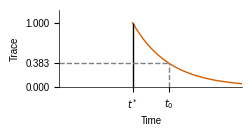

In [52]:
fig, ax = plt.subplots(1, 1, figsize=figsize)

spike_pos = 400
color = "#D55E00"

x = np.zeros(1000)
x[spike_pos] = 1
y = trace_over(x, beta=0.995)

ax.plot(np.where(y>0, y, np.nan), c=color)
ax.vlines(x=400, ymin=0, ymax=1, colors="black")
ax.vlines(x=600, ymin=0, ymax=0.37, colors="gray", linestyles="--")
ax.hlines(y=0.37, xmin=0, xmax=600, colors="gray", linestyles="--")

ax.set_ylim(0, 1+0.2)
ax.set_xlim(0, 1000)

ax.set_xlabel("Time")
ax.set_ylabel("Trace")

ax.set_xticks([400, 600], labels=["$t^*$", "$t_0$"])
ax.set_yticks([0, 0.37, 1], ["0.000", "0.383", "1.000"])

if save_plots:
    # fig.tight_layout()
    fig.savefig(dir_path + "forward_rec.svg", bbox_inches='tight')

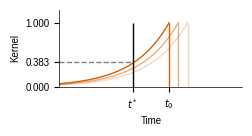

In [53]:
fig, ax = plt.subplots(1, 1, figsize=figsize)
offset = 50
beta = 0.995
color = "#D55E00"

x = np.zeros(1000)
x[spike_pos] = 1
y = trace_over(x, beta=beta)

x1 = np.zeros(1000)
x1[spike_pos - offset] = 1
y1 = trace_over(x1, beta=beta)

x2 = np.zeros(1000)
x2[spike_pos - 2* offset] = 1
y2 = trace_over(x2, beta=beta)

ax.plot(np.where(y[::-1]>0, y[::-1], np.nan), c=color, alpha=1)
ax.plot(np.where(y1[::-1]>0, y1[::-1], np.nan), c=color, alpha=0.5)
ax.plot(np.where(y2[::-1]>0, y2[::-1], np.nan), c=color, alpha=0.25)

ax.vlines(x=1000-spike_pos, ymin=0, ymax=1, colors=color)
ax.vlines(x=1000-spike_pos+offset, ymin=0, ymax=1, colors=color, alpha=0.5)
ax.vlines(x=1000-spike_pos+2*offset, ymin=0, ymax=1, colors=color, alpha=0.25)

ax.vlines(x=400, ymin=0, ymax=1, colors="black")

ax.set_ylim(0, 1+0.2)
ax.set_xlim(0, 1000)

ax.set_xlabel("Time")
ax.set_ylabel("Kernel")

ax.hlines(y=0.383, xmin=0, xmax=400, linestyles="--", colors="gray")
ax.set_xticks([400, 600], labels=["$t^*$", "$t_0$"])
ax.set_yticks([0, 0.383, 1])

if save_plots:
    fig.savefig(dir_path + "conv.svg", bbox_inches='tight')

# TDCL Kernel

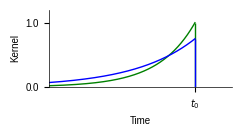

In [54]:
fig, ax = plt.subplots(1, 1, figsize=figsize)
offset = 50
beta = 0.995

x = np.zeros(1000)
x[200] = 1
y1 = trace_over(x, beta=beta)
y1 = np.where(y1[::-1]>0, y1[::-1], np.nan)
ax.plot(y1, c="green", alpha=1)
ax.vlines(x=1000-200, ymin=0, ymax=1, colors="green")

y2 = trace_over(x, beta=beta+0.002)
y2 = np.where(y2[::-1]>0, 0.75*y2[::-1], np.nan)
ax.plot(y2, c="blue", alpha=1)
ax.vlines(x=1000-200, ymin=0, ymax=0.75, colors="blue")

ax.set_ylim(0, 1+0.2)
ax.set_xlim(0, 1000)

ax.set_xlabel("Time")
ax.set_ylabel("Kernel")

ax.set_xticks([1000-200], labels=["$t_0$"])
ax.set_yticks([0, 1], ["0.0", "1.0"])

if save_plots:
    fig.savefig(dir_path + "fast_over_slow.svg", bbox_inches='tight')

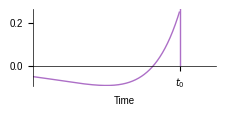

In [55]:
fig, ax = plt.subplots(1, 1, figsize=figsize)
offset = 50
beta = 0.995
color = "#ad6fc7"

y3 = y1 - y2
ax.plot(y3, c=color, alpha=1)
ax.vlines(x=1000-200, ymin=0, ymax=1, colors=color)

ymin = y3[:800].min()
ymin += 0.05 * ymin
ymax = y3[:800].max()
ymax += 0.05 * ymax
ax.set_ylim(ymin=ymin, ymax=ymax)
ax.set_xlim(0, 1000)

ax.set_xlabel("Time")
ax.set_xticks([1000-200], labels=["$t_0$"])
ax.spines['bottom'].set_position('zero')

if save_plots:
    fig.savefig(dir_path + "fast_over_slow_kernel_red.svg", bbox_inches='tight')

# Overpowered Kernel

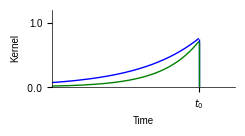

In [56]:
fig, ax = plt.subplots(1, 1, figsize=figsize)
offset = 50
beta = 0.995

x = np.zeros(1000)
x[200] = 1
y1 = trace_over(x, beta=beta)
y1 = np.where(y1[::-1]>0, 0.7*y1[::-1], np.nan)
ax.plot(y1, c="green", alpha=1)

y2 = trace_over(x, beta=beta+0.002)
y2 = np.where(y2[::-1]>0, 0.75*y2[::-1], np.nan)
ax.plot(y2, c="blue", alpha=1)

ax.vlines(x=1000-200, ymin=0, ymax=0.75, colors="blue")
ax.vlines(x=1000-200, ymin=0, ymax=0.7, colors="green")

ax.set_ylim(0, 1+0.2)
ax.set_xlim(0, 1000)

ax.set_xlabel("Time")
ax.set_ylabel("Kernel")

ax.set_xticks([1000-200], labels=["$t_0$"])
ax.set_yticks([ 0, 1], ["$0.0$", "1.0"])

if save_plots:
    fig.savefig(dir_path + "slow_over_fast.svg", bbox_inches='tight')

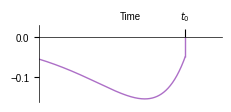

In [57]:
fig, ax = plt.subplots(1, 1, figsize=figsize)
offset = 50
beta = 0.995
color = "#ad6fc7"

y3 = y1 - y2
ax.plot(y3, c=color, alpha=1)
ax.vlines(x=1000-200, ymin=-0.05, ymax=0, colors=color)

ymin = y3[:800].min()
ymin += 0.05 * ymin
ymax = 0.03
ax.set_ylim(ymin=ymin, ymax=ymax)
ax.set_xlim(0, 1000)

ax.set_xticks([1000-200], labels=["$t_0$"])
ax.xaxis.set_ticks_position('bottom')
ax.xaxis.set_label_position('top')
ax.tick_params(axis='x', direction='in', length=6, pad=-20,)
ax.spines['bottom'].set_position('zero')

ax.set_xlabel("Time")
# ax.set_ylabel("Kernel Difference\n(Fast - Slow)")

if save_plots:
    fig.savefig(dir_path + "slow_over_fast_kernel_red.svg", bbox_inches='tight')